# Budget setting

Minimize the terminal generalization error $\varepsilon_{g,t_F}$ subject to a cap
$\gamma$ on the time-averaged query rate.

Set `RECOMPUTE = True` to redo the optimization and the simulations from
scratch (about 22 min). Otherwise both are read from `results/`.

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import adatron as A, optimize as O, plotting as P

RECOMPUTE = False
p = A.Params()
GAMMAS = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
D = 1000
os.makedirs('results', exist_ok=True)
os.makedirs('figures', exist_ok=True)
p

Params(eta=0.5, m0=0.0, q0=0.15, t_F=20.0, n_steps=2000)

## Optimal policies

In [2]:
if RECOMPUTE or not os.path.exists('results/budget.npz'):
    np.savez('results/budget.npz', **O.sweep_budget(p, GAMMAS))
ode = dict(np.load('results/budget.npz'))

print(' gamma  ' + '  '.join('%8s' % k for k in O.KEYS))
for i, g in enumerate(ode['gammas']):
    print('%6.2f  ' % g + '  '.join('%8.4f' % ode['eps_' + k][i] for k in O.KEYS))
print()
print('realized budget, worst deviation from nominal: %.1e'
      % max(np.abs(ode['bud_' + k] - ode['gammas']).max() for k in O.KEYS))

 gamma     local      cmar      smar      cann      sann      rand
  0.10    0.3425    0.4920    0.4066    0.3489    0.3237    0.4063
  0.20    0.2737    0.4681    0.3304    0.2790    0.2494    0.3306
  0.30    0.2245    0.4282    0.2727    0.2331    0.2013    0.2727
  0.40    0.1868    0.3729    0.2272    0.2007    0.1678    0.2293
  0.50    0.1571    0.3049    0.1912    0.1758    0.1444    0.1963
  0.60    0.1357    0.2335    0.1619    0.1560    0.1287    0.1709
  0.70    0.1220    0.1778    0.1376    0.1397    0.1188    0.1509
  0.80    0.1144    0.1454    0.1182    0.1259    0.1134    0.1349
  0.90    0.1113    0.1265    0.1115    0.1156    0.1113    0.1218
  1.00    0.1110    0.1110    0.1110    0.1110    0.1110    0.1110

realized budget, worst deviation from nominal: 1.5e-04


## Finite-$d$ SGD simulations

Each optimized policy is replayed on a fresh Gaussian stream at $d=1000$, one
run per point with no averaging, so the scatter around the curves is the honest
size of the finite-$d$ correction. The policies are the same objects the ODEs
were integrated with, so theory and simulation cannot disagree about which set
is being selected.

In [3]:
def sim_budget():
    eps = {k: np.zeros(len(GAMMAS)) for k in O.KEYS}
    for i, g in enumerate(GAMMAS):
        policies = {
            'local': A.LocalBudget(float(ode['nu'][i]), p.eta),
            'cmar':  A.Margin(float(ode['kappa'][i])),
            'smar':  A.MarginSchedule(ode['kap_sched'][i], p.t_F),
            'cann':  A.Annulus(float(ode['a_const'][i]), float(ode['b_const'][i])),
            'sann':  A.Schedule(ode['a_sched'][i], ode['b_sched'][i], p.t_F),
            'rand':  A.Random(float(ode['p_rand'][i]))}
        for k in O.KEYS:
            eps[k][i] = A.simulate(policies[k], p, d=D, seed=100 + i)['eps'][0]
        print('gamma=%.2f done' % g, flush=True)
    out = {'gammas': GAMMAS}
    out.update({'eps_' + k: eps[k] for k in O.KEYS})
    return out

if RECOMPUTE or not os.path.exists('results/sim_budget.npz'):
    np.savez('results/sim_budget.npz', **sim_budget())
sim = dict(np.load('results/sim_budget.npz'))
print('max |ODE - SGD| = %.4f' % max(np.abs(ode['eps_'+k]-sim['eps_'+k]).max()
                                     for k in O.KEYS))

max |ODE - SGD| = 0.0084


## Figure: terminal error versus budget

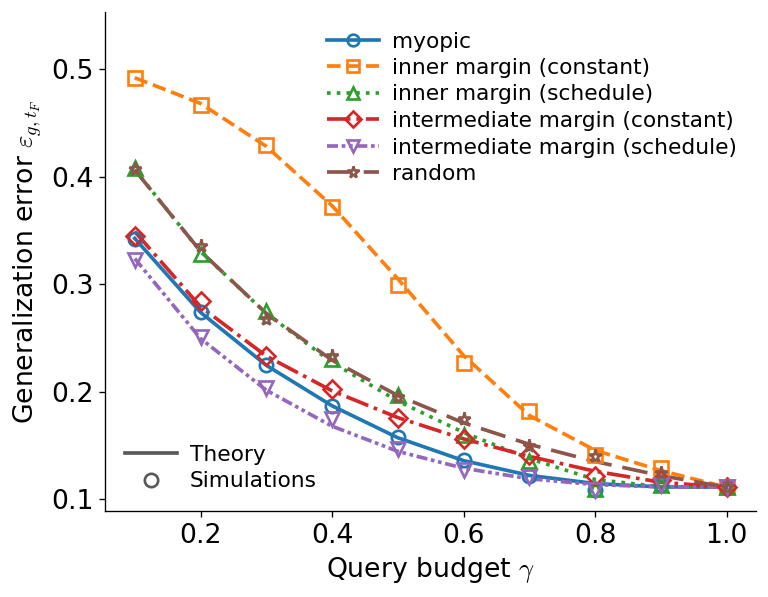

In [4]:
fig, ax = P.curve_figure(ode['gammas'], ode, sim, 'eps_', 'eps_',
                         r'Query budget $\gamma$',
                         r'Generalization error $\varepsilon_{g,t_F}$',
                         loc='upper right')
fig.savefig('figures/fig_budget.pdf')

## Figure: selection map at one budget

The myopic rule and the horizon-optimized schedule overlaid. Both are
intermediate margins, with a hole at the decision boundary where the update
magnitude vanishes; the horizon-optimized schedule opens a wider hole early and
keeps querying to the end. The myopic rule's outer radius extends
beyond the plotted range at early times, and its band stops near $t=18$: at a
fixed shadow price no sample is worth querying any more, so the myopic rule
stops entirely and its order parameters freeze.

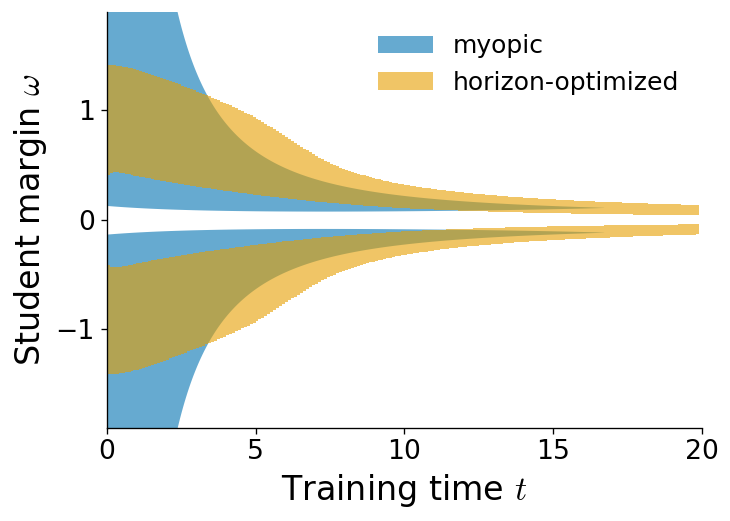

In [5]:
GAM = 0.4
i = int(np.argmin(np.abs(ode['gammas'] - GAM)))

if RECOMPUTE or not os.path.exists('results/selmap_budget.npz'):
    t_loc, lo_loc, hi_loc = O.local_support_trace(p, float(ode['nu'][i]))
    a_fine, b_fine = O.refine_schedule(p, ode['a_sched'][i], ode['b_sched'][i],
                                       'budget', gamma=GAM)
    np.savez('results/selmap_budget.npz', t_loc=t_loc, lo_loc=lo_loc,
             hi_loc=hi_loc, a_fine=a_fine, b_fine=b_fine)
S = dict(np.load('results/selmap_budget.npz'))

t_fine = (p.t_F / len(S['a_fine'])) * np.arange(len(S['a_fine']))
fig, ax = P.selection_overlay(
    P.Band(S['t_loc'], S['lo_loc'], S['hi_loc'], step=False, mirror=True),
    P.Band(t_fine,     S['a_fine'], S['b_fine'], step=True,  mirror=True),
    p.t_F)
fig.savefig('figures/fig_sel_budget.pdf')